In [1]:
# -----------------------------------------------------------------------
# Libraries and Reproducibility setup
# -----------------------------------------------------------------------

import sys
import warnings
import numpy as np
import matplotlib
import scipy
import sklearn
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (Matern, ConstantKernel, WhiteKernel, RBF)
from scipy.stats import norm, qmc
from scipy.optimize import minimize
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 42
np.random.seed(SEED)

print("=" * 100)
print("Software and Libraries used")
print("=" * 100)
print(f"  python      : {sys.version.split()[0]}")
print(f"  numpy       : {np.__version__}")
print(f"  scipy       : {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")
print(f"  SEED        : {SEED}")
print()


# ---------------------------------------------------------------- figures
SURFACE, INK, INK2, MUTED, GRIDC = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e6e5e1"
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#e34948"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": INK, "axes.edgecolor": MUTED, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRIDC, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    })

Software and Libraries used
  python      : 3.13.9
  numpy       : 2.3.5
  scipy       : 1.16.3
  scikit-learn: 1.9.0
  matplotlib  : 3.11.1
  SEED        : 42



In [2]:
# --------------------------------------------------------------------- #
# DATA
# --------------------------------------------------------------------- #
X = np.load('..\Function_8_Data\Week_13_Data/F8_Week_13_inputs.npy')
y = np.load('..\Function_8_Data\Week_13_Data/F8_Week_13_outputs.npy')
n, d = X.shape
N_INITIAL = 40
NEW = n - 1
best = int(np.argmax(y))
xb = X[best]
prev_best = int(np.argmax(y[:NEW]))
print(f"n = {n} ({N_INITIAL} initial + {n - N_INITIAL} queried)")
#print(f"row 48 as stored: {y[48]:.10f} (corrected value; the week-11 file had 0.9647925911)")
print(f"Newest x = {np.round(X[NEW], 6)}, y = {y[NEW]:.6f}; best observed row {best}, y = {y[best]:.6f}; "
      f"\nPrevious best {y[prev_best]:.6f} (row {prev_best}); gain {y[best] - y[prev_best]:+.6f}")
print(f"Step from the previous best to the newest point: length {np.linalg.norm(X[NEW] - X[prev_best]):.3f}")

n = 52 (40 initial + 12 queried)
Newest x = [0.102203 0.148136 0.128931 0.146435 0.803198 0.503648 0.192009 0.590191], y = 9.999815; best observed row 51, y = 9.999815; 
Previous best 9.999697 (row 50); gain +0.000118
Step from the previous best to the newest point: length 0.009


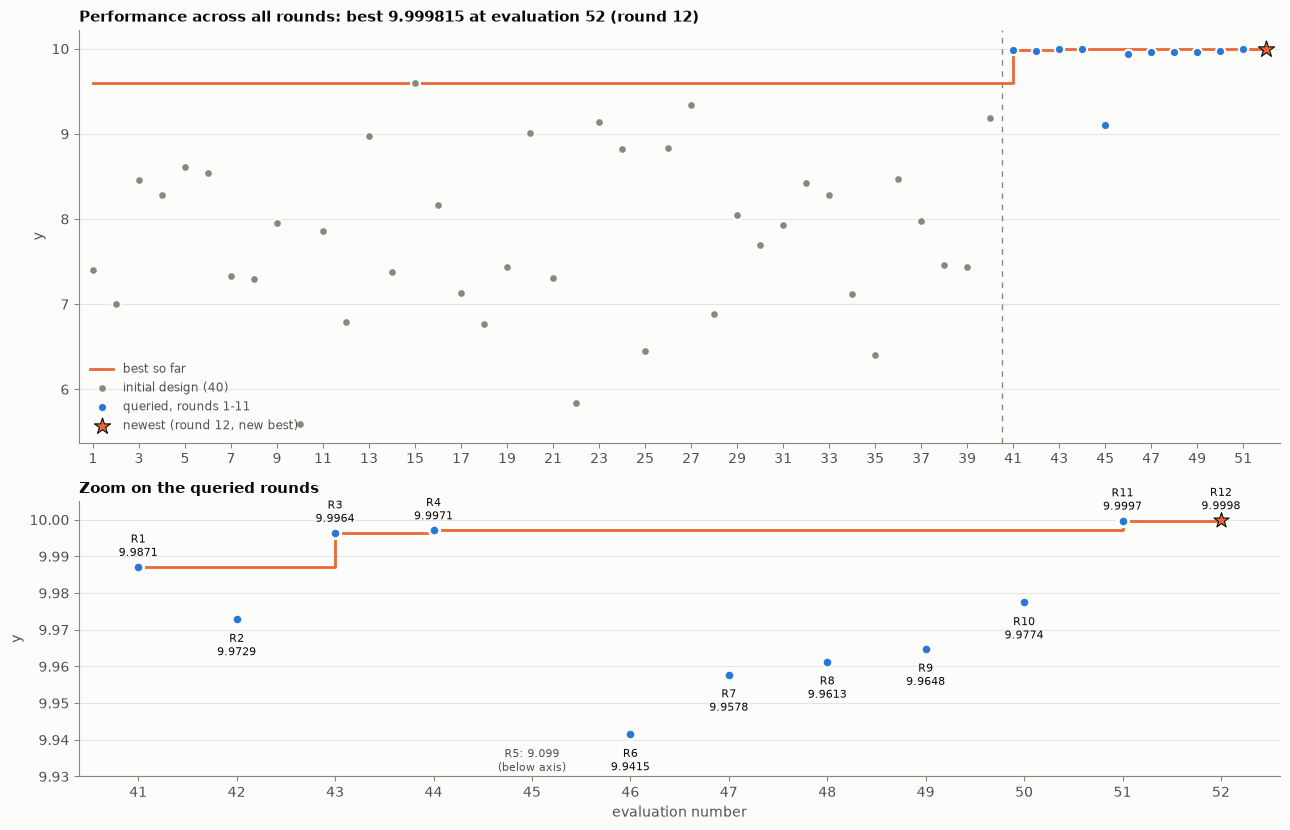

In [3]:
# Fig 1: performance across all rounds
idx = np.arange(1, n + 1)
bsf = np.maximum.accumulate(np.r_[np.full(N_INITIAL, y[:N_INITIAL].max()), y[N_INITIAL:]])
fig, (ax, az) = plt.subplots(2, 1, figsize=(13, 8.4), height_ratios=[3, 2])
ax.axvline(N_INITIAL + 0.5, color=MUTED, lw=1, ls=(0, (4, 4)))
ax.step(idx, bsf, where="post", color=PAL[1], lw=2, label="best so far", zorder=2)
ax.scatter(idx[:N_INITIAL], y[:N_INITIAL], s=40, color=MUTED, edgecolor=SURFACE, linewidth=1.5, label=f"initial design ({N_INITIAL})", zorder=3)
ax.scatter(idx[N_INITIAL:NEW], y[N_INITIAL:NEW], s=45, color=PAL[0], edgecolor=SURFACE, linewidth=1.5,
           label=f"queried, rounds 1-{n - N_INITIAL - 1}", zorder=3)
ax.scatter(idx[NEW], y[NEW], s=150, marker="*", color=PAL[1], edgecolor=INK, linewidth=0.8, zorder=4, label=f"newest (round {n - N_INITIAL}" + (", new best)" if NEW == best else ")"))
ax.set_xticks(idx[::2]); ax.set_xlim(0.4, n + 0.6); ax.grid(axis="x", visible=False); ax.set_ylabel("y")
ax.set_title(f"Performance across all rounds: best {y[best]:.6f} at evaluation {best + 1} (round {best - N_INITIAL + 1})")
ax.legend(frameon=False, loc="lower left", fontsize=8.5, labelcolor=INK2)
q = np.arange(N_INITIAL, n)
az.step(idx[q], bsf[q], where="post", color=PAL[1], lw=2, zorder=2)
for i in q:
    star = i == NEW
    if y[i] >= 9.9:
        az.scatter(idx[i], y[i], s=130 if star else 56, marker="*" if star else "o", color=PAL[1] if star else PAL[0],
                   edgecolor=INK if star else SURFACE, linewidth=0.8 if star else 2, zorder=3)
        az.annotate(f"R{i - N_INITIAL + 1}\n{y[i]:.4f}", (idx[i], y[i]), xytext=(0, 8 if y[i] >= bsf[i] - 1e-12 else -26),
                    textcoords="offset points", ha="center", fontsize=8, color=INK)
    else:
        az.annotate(f"R{i - N_INITIAL + 1}: {y[i]:.3f}\n(below axis)", (idx[i], 9.93), xytext=(0, 4),
                    textcoords="offset points", ha="center", fontsize=8, color=INK2)
az.set_ylim(9.93, 10.005); az.set_xticks(idx[q]); az.set_xlim(N_INITIAL + 0.4, n + 0.6)
az.grid(axis="x", visible=False); az.set_xlabel("evaluation number"); az.set_ylabel("y")
az.set_title("Zoom on the queried rounds")
fig.tight_layout()

Skewness of y: -0.120


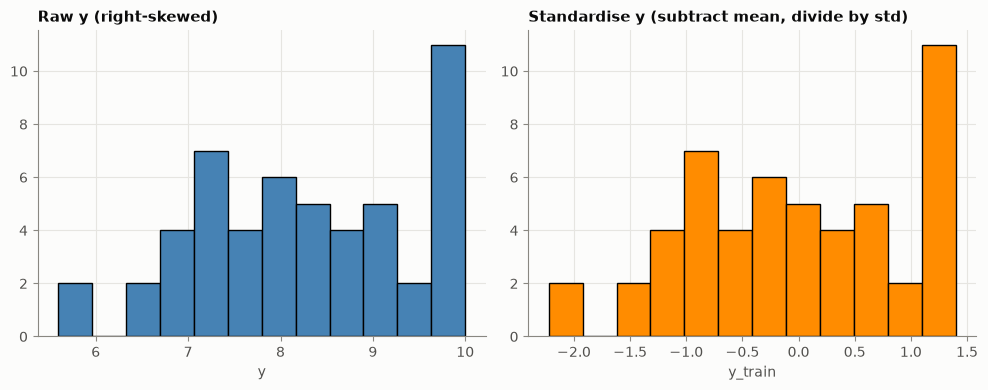

In [4]:
# --------------------------------------------------------------------- #
# DATA TRANSFORMATION
# --------------------------------------------------------------------- #
# INPUTS
# ------
# All 8 columns already lie in (a numerical approximation of) [0, 1].

X_train = X.copy()
bounds = np.array([[0.0, 1.0]] * d)  # search domain for the acquisition optimiser

# OUTPUTS
# -------
# y ranges from ~5.6 to ~10.0 with a non-zero mean (~7.9) and no obvious
# skew/heavy tail (a quick skewness check below confirms this). 
# Standardise y (subtract mean, divide by std) before fitting.
# Convert GP predictions back to the original scale for reporting/plotting.

from scipy.stats import skew
print(f"Skewness of y: {skew(y):.3f}")

y_mean, y_std = y.mean(), y.std()
y_train = (y - y_mean) / y_std

def unstandardise(mu_s, sigma_s):
    """Map standardised GP posterior mean/std back to the original y scale."""
    return mu_s * y_std + y_mean, sigma_s * y_std

# Fig. 2: Target Transformation
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(y, bins=12, color="steelblue", edgecolor="k")
axes[0].set_title("Raw y (right-skewed)")
axes[0].set_xlabel("y")
axes[1].hist(y_train, bins=12, color="darkorange", edgecolor="k")
axes[1].set_title("Standardise y (subtract mean, divide by std)")
axes[1].set_xlabel("y_train")
plt.tight_layout()

In [5]:
# ---------------------------------------------------------------- 
# Models
# ---------------------------------------------------------------- 

def kern(kind, ard=True):
    ls = np.ones(d) if ard else 1.0
    if kind == "rbf":
        base = RBF(length_scale=ls, length_scale_bounds=(1e-2, 1e2))
    else:
        base = Matern(length_scale=ls, length_scale_bounds=(1e-2, 1e2), nu=kind)
    return ConstantKernel(1.0, (1e-2, 1e2)) * base + WhiteKernel(1e-3, (1e-6, 1e-1))

def fit(Xf, yy, kind=2.5, ard=True):
    t = (yy - yy.mean()) / yy.std()
    gp = GaussianProcessRegressor(kernel=kern(kind, ard), alpha=1e-8, n_restarts_optimizer=15, random_state=SEED).fit(Xf, t)
    return gp, yy.mean(), yy.std()

def loo(model, yy):
    gp, m0, s0 = model
    t = (yy - m0) / s0
    mu, sd = np.empty(n), np.empty(n)
    for i in range(n):
        keep = np.arange(n) != i
        g = GaussianProcessRegressor(kernel=gp.kernel_, optimizer=None, alpha=1e-8).fit(X[keep], t[keep])
        a, s = g.predict(X[i:i + 1], return_std=True)
        mu[i], sd[i] = a[0] * s0 + m0, s[0] * s0
    return mu, sd

SPECS = {"Matern 5/2 ARD": (2.5, True), "Matern 5/2 isotropic": (2.5, False),
         "Matern 3/2 ARD": (1.5, True), "RBF ARD": ("rbf", True)}
top = np.argsort(-y)[:8]
runs = {}
print("\nMODELS (LOO with hyperparameters fixed at the full fit)")
for key, (kind, ard) in SPECS.items():
    model = fit(X, y, kind, ard)
    mu, sd = loo(model, y)
    runs[key] = (model, mu, sd)
    ls = np.atleast_1d(model[0].kernel_.k1.k2.length_scale)
    on_bound = [j + 1 for j, v in enumerate(ls) if np.isclose(v, 1e-2, rtol=1e-3) or np.isclose(v, 1e2, rtol=1e-3)]
    r2 = 1 - np.sum((y - mu) ** 2) / np.sum((y - y.mean()) ** 2)
    print(f"  {key:30s} ls={np.round(ls, 2)}  LML={model[0].log_marginal_likelihood_value_:.2f}  LOO R2={r2:.4f}  "
          f"RMSE/std={np.sqrt(np.mean((y - mu) ** 2)) / y.std():.3f}  top-8 RMSE={np.sqrt(np.mean((y[top] - mu[top]) ** 2)):.4f}  "
          f"newest point (LOO) {mu[NEW]:.4f}  on a bound: {on_bound}")
REC = "Matern 5/2 ARD"
(gp, m0, s0), mu_rec, sd_rec = runs[REC]
print(f"\nRecommended model: {gp.kernel_}")

def pmean(Z, key=REC):
    g, a, b = runs[key][0]
    return g.predict(np.atleast_2d(Z)) * b + a

def psd(Z, key=REC):
    g, a, b = runs[key][0]
    return g.predict(np.atleast_2d(Z), return_std=True)[1] * b


MODELS (LOO with hyperparameters fixed at the full fit)
  Matern 5/2 ARD                 ls=[ 7.04 10.09  5.77  9.75 13.98 10.16  7.15 28.79]  LML=41.50  LOO R2=0.9993  RMSE/std=0.026  top-8 RMSE=0.0038  newest point (LOO) 9.9997  on a bound: []
  Matern 5/2 isotropic           ls=[5.67]  LML=12.99  LOO R2=0.9896  RMSE/std=0.102  top-8 RMSE=0.0065  newest point (LOO) 9.9995  on a bound: []
  Matern 3/2 ARD                 ls=[10.33 16.23  8.2  15.79 27.4  16.07 10.87 80.63]  LML=35.03  LOO R2=0.9963  RMSE/std=0.061  top-8 RMSE=0.0058  newest point (LOO) 9.9999  on a bound: []
  RBF ARD                        ls=[1.53 2.08 1.18 6.4  2.74 2.66 1.52 4.76]  LML=26.39  LOO R2=0.9962  RMSE/std=0.062  top-8 RMSE=0.0085  newest point (LOO) 9.9997  on a bound: []

Recommended model: 10**2 * Matern(length_scale=[7.04, 10.1, 5.77, 9.75, 14, 10.2, 7.15, 28.8], nu=2.5) + WhiteKernel(noise_level=1e-06)


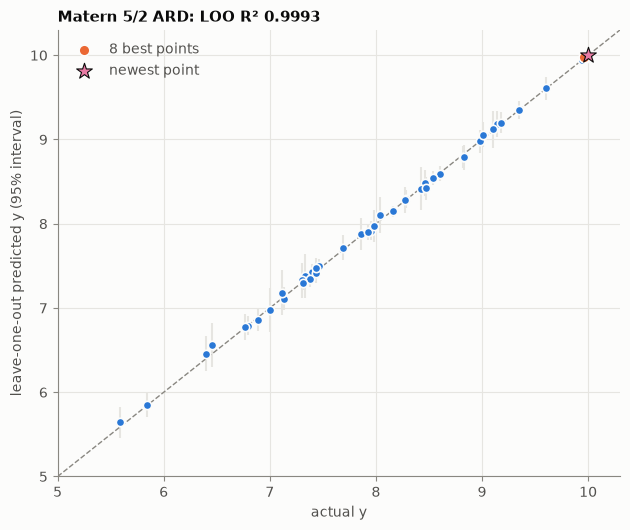

In [6]:
# Fig 3: LOO for the recommended model
fig, ax = plt.subplots(figsize=(6.4, 5.4))
lim = [5, 10.3]
ax.plot(lim, lim, color=MUTED, lw=1, ls="--")
ax.errorbar(y, mu_rec, yerr=1.96 * sd_rec, fmt="none", ecolor=GRIDC, elinewidth=1.5, zorder=1)
ax.scatter(y, mu_rec, s=36, color=PAL[0], edgecolor=SURFACE, linewidth=1.2, zorder=3)
ax.scatter(y[top], mu_rec[top], s=60, color=PAL[1], edgecolor=SURFACE, linewidth=1.2, zorder=4, label="8 best points")
ax.scatter(y[NEW], mu_rec[NEW], s=140, marker="*", color=PAL[4], edgecolor=INK, linewidth=0.8, zorder=5, label="newest point")
r2 = 1 - np.sum((y - mu_rec) ** 2) / np.sum((y - y.mean()) ** 2)
ax.set_xlim(lim); ax.set_ylim(lim); ax.set_xlabel("actual y"); ax.set_ylabel("leave-one-out predicted y (95% interval)")
ax.set_title(f"Matern 5/2 ARD: LOO R² {r2:.4f}")
ax.legend(frameon=False, loc="upper left", labelcolor=INK2)
fig.tight_layout()


WEEK-12 PREDICTIONS at the newest point (models refitted on the first 51 rows); observed 9.999815
  Matern 5/2 ARD                 predicted 9.99973 +/- 0.00193   error +0.00009   z = +0.05
  Matern 5/2 isotropic           predicted 9.99947 +/- 0.00226   error +0.00035   z = +0.15
  Matern 3/2 ARD                 predicted 9.99986 +/- 0.00227   error -0.00005   z = -0.02
  RBF ARD                        predicted 9.99974 +/- 0.00200   error +0.00008   z = +0.04




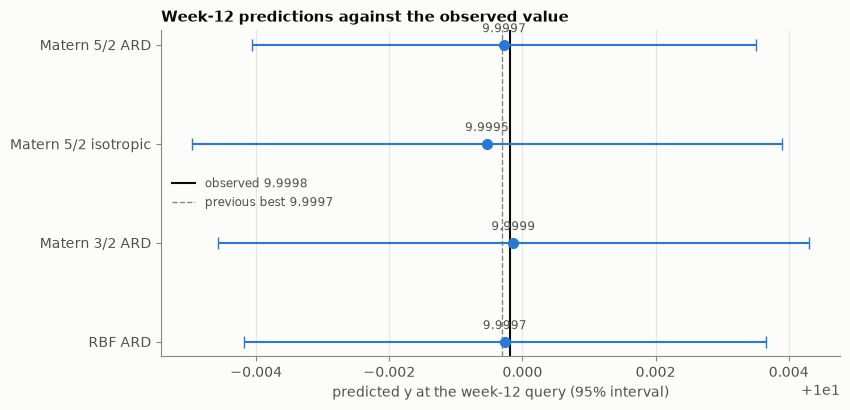

In [7]:
# ---------------------------------------------------------------- 
# Week-12 predictions check
# ---------------------------------------------------------------- 
print(f"\nWEEK-12 PREDICTIONS at the newest point (models refitted on the first {NEW} rows); observed {y[NEW]:.6f}")
prev_pred = {}
for key, (kind, ard) in SPECS.items():
    g, a, b = fit(X[:NEW], y[:NEW], kind, ard)
    m, s = g.predict(X[NEW:NEW + 1], return_std=True)
    prev_pred[key] = (m[0] * b + a, s[0] * b)
    print(f"  {key:30s} predicted {m[0] * b + a:.5f} +/- {s[0] * b:.5f}   error {y[NEW] - (m[0] * b + a):+.5f}   z = {(y[NEW] - (m[0] * b + a)) / (s[0] * b):+.2f}")

print('\n')
# Fig 4: week-12 predictions vs outcome
fig, ax = plt.subplots(figsize=(8.6, 4.2))
KEYS = list(SPECS)
names = KEYS
vals = [prev_pred[k][0] for k in names]
sds = [prev_pred[k][1] for k in names]
ypos = np.arange(len(names))[::-1]
ax.errorbar(vals, ypos, xerr=[1.96 * s_ for s_ in sds], fmt="o", color=PAL[0], capsize=4, lw=1.5, ms=7, zorder=3)
for v_, p_ in zip(vals, ypos):
    ax.annotate(f"{v_:.4f}", (v_, p_), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=8.5, color=INK2)
ax.axvline(y[NEW], color=INK, lw=1.5, label=f"observed {y[NEW]:.4f}")
ax.axvline(y[prev_best], color=MUTED, lw=1, ls="--", label=f"previous best {y[prev_best]:.4f}")
ax.set_yticks(ypos); ax.set_yticklabels([k.split(" (")[0] for k in names])
ax.set_xlabel("predicted y at the week-12 query (95% interval)")
ax.set_title("Week-12 predictions against the observed value")
ax.legend(frameon=False, loc="center left", fontsize=8.5, labelcolor=INK2)
ax.grid(axis="y", visible=False)
fig.tight_layout()

In [8]:
# ---------------------------------------------------------------- 
# Parametric check: maximum minus weighted squared distances
# ---------------------------------------------------------------- 
from scipy.optimize import least_squares

def quad_fit(rows, starts):
    def res(p):
        return p[0] - ((X[rows] - p[1:1 + d]) ** 2 * np.exp(p[1 + d:])).sum(1) - y[rows]
    best_r = None
    for p0 in starts:
        r = least_squares(res, p0, xtol=1e-14, ftol=1e-14, gtol=1e-14)
        if best_r is None or r.cost < best_r.cost:
            best_r = r
    return best_r

def quad_pred(p, Z):
    return p[0] - ((np.atleast_2d(Z) - p[1:1 + d]) ** 2 * np.exp(p[1 + d:])).sum(1)

rng = np.random.default_rng(SEED)
starts_all = [np.r_[10.0, X[best], np.full(d, np.log(5.0))]] + [np.r_[10.0, rng.random(d), rng.normal(1, 1, d)] for _ in range(20)]
allrows = np.arange(n)
qa = quad_fit(allrows, starts_all)
q_p = qa.x
q_M, q_c, q_w = q_p[0], q_p[1:1 + d], np.exp(q_p[1 + d:])
q_res = y - quad_pred(q_p, X)
print("\nSEPARABLE QUADRATIC  y = M - sum_j w_j (x_j - c_j)^2  fitted to all rows (17 parameters, 52 rows)")
print(f"  M = {q_M:.9f}   max |residual| = {np.abs(q_res).max():.2e}")
print("  c = " + np.array2string(q_c, precision=6, suppress_small=True))
print("  w = " + np.array2string(q_w, precision=6, suppress_small=True))
x_vertex = np.clip(q_c, 0, 1)
print(f"  vertex inside the unit cube: {bool(np.all((q_c >= 0) & (q_c <= 1)))}; predicted y at the vertex = {quad_pred(q_p, x_vertex)[0]:.9f}")
# out of sample: fit on the first k rows only, predict the rows that follow
print("  out-of-sample: fit on the first k rows only, predict the rows that follow")
qo_pred, qo_true, qo_rest = None, None, None
for k in (40, 45, 50):
    rows = np.arange(k)
    r = quad_fit(rows, starts_all)
    rest = np.arange(k, n)
    e = y[rest] - quad_pred(r.x, X[rest])
    print(f"    k = {k}: in-sample max |res| {np.abs(r.fun).max():.1e};  next {len(rest)} rows max |error| {np.abs(e).max():.2e};  "
          f"M = {r.x[0]:.6f}, centre moved by {np.linalg.norm(r.x[1:1 + d] - q_c):.1e}")
    if k == N_INITIAL:
        qo_pred, qo_true, qo_rest = quad_pred(r.x, X[rest]), y[rest], rest


SEPARABLE QUADRATIC  y = M - sum_j w_j (x_j - c_j)^2  fitted to all rows (17 parameters, 52 rows)
  M = 10.000000000   max |residual| = 1.78e-15
  c = [0.1  0.15 0.13 0.15 0.8  0.5  0.2  0.6 ]
  w = [2.  1.  3.  1.  0.5 1.  2.  0.1]
  vertex inside the unit cube: True; predicted y at the vertex = 10.000000000
  out-of-sample: fit on the first k rows only, predict the rows that follow
    k = 40: in-sample max |res| 8.9e-16;  next 12 rows max |error| 1.78e-15;  M = 10.000000, centre moved by 3.3e-15
    k = 45: in-sample max |res| 1.8e-15;  next 7 rows max |error| 1.78e-15;  M = 10.000000, centre moved by 1.5e-15
    k = 50: in-sample max |res| 1.8e-15;  next 2 rows max |error| 0.00e+00;  M = 10.000000, centre moved by 1.7e-15


In [9]:
# ---------------------------------------------------------------- 
# Candidates
# ---------------------------------------------------------------- 

f_inc = gp.predict(X).max()
def ei(Z):
    m, s = gp.predict(np.atleast_2d(Z), return_std=True)
    s = np.maximum(s, 1e-12)
    z = (m - f_inc) / s
    return (m - f_inc) * norm.cdf(z) + s * norm.pdf(z)

S = qmc.Sobol(d, seed=1).random(2 ** 15)
def box_argmax(fn, r, centre=None):
    c = xb if centre is None else centre
    lo, hi = np.clip(c - r, 0, 1), np.clip(c + r, 0, 1)
    Z = np.vstack([lo + S * (hi - lo), X[np.all((X >= lo) & (X <= hi), axis=1)]])
    v = fn(Z); x0 = Z[v.argmax()]
    res = minimize(lambda q: -fn(q[None])[0], x0, bounds=list(zip(lo, hi)), method="L-BFGS-B")
    return res.x if -res.fun >= v.max() else x0

KEYS = list(SPECS)
base = {k: pmean(xb, k)[0] for k in KEYS}
ens = lambda Z: np.mean([pmean(Z, k) - base[k] for k in ["Matern 5/2 ARD", "Matern 3/2 ARD", "RBF ARD"]], axis=0)
x_m52 = box_argmax(lambda Z: pmean(Z, REC), 0.05)
x_m32 = box_argmax(lambda Z: pmean(Z, "Matern 3/2 ARD"), 0.1)
x_rbf = box_argmax(lambda Z: pmean(Z, "RBF ARD"), 0.1)
cands = {
    "A: EI +/-0.05": box_argmax(ei, 0.05),
    "B: Matern 5/2 max": x_m52,
    "C: Matern 3/2 max (+/-0.1)": x_m32,
    "D: RBF max (+/-0.1)": x_rbf,
    "E: ensemble max (+/-0.05)": box_argmax(ens, 0.05),
}
cands["F: half-step B to E"] = xb + 0.5 * (cands["E: ensemble max (+/-0.05)"] - xb)
cands["G: vertex of the fitted quadratic"] = x_vertex
gains = {}
print(f"\nCANDIDATES (best observed {y[best]:.6f}; each model's prediction at the best point:\n"
      + "\n".join(f"{k.split(' (')[0]} {v:.5f}" for k, v in base.items()) + ")")
print('\n')
for name, xc in cands.items():
    p = {k: pmean(xc, k)[0] for k in KEYS}
    gains[name] = {k: p[k] - base[k] for k in KEYS}
    print(f"{name:30s} \n   x = ({', '.join(f'{v:.6f}' for v in xc)})  \n   dist {np.linalg.norm(xc - xb):.3f}")
    print(f"   Matern 5/2 ARD predicted {p[REC]:.5f} +/- {psd(xc)[0]:.5f};\n   predicted gain over each model's own best-point value:\n"
          + "\n".join(f"   {k.split(' (')[0]}={v:+.5f}" for k, v in gains[name].items()))


CANDIDATES (best observed 9.999815; each model's prediction at the best point:
Matern 5/2 ARD 9.99978
Matern 5/2 isotropic 9.99972
Matern 3/2 ARD 9.99983
RBF ARD 9.99979)


A: EI +/-0.05                  
   x = (0.071254, 0.158452, 0.122063, 0.125649, 0.811010, 0.453648, 0.212018, 0.557884)  
   dist 0.074
   Matern 5/2 ARD predicted 9.99399 +/- 0.01136;
   predicted gain over each model's own best-point value:
   Matern 5/2 ARD=-0.00579
   Matern 5/2 isotropic=+0.00668
   Matern 3/2 ARD=-0.01725
   RBF ARD=+0.00840
B: Matern 5/2 max              
   x = (0.102061, 0.147764, 0.129013, 0.146260, 0.803037, 0.503518, 0.192808, 0.590322)  
   dist 0.001
   Matern 5/2 ARD predicted 9.99978 +/- 0.00156;
   predicted gain over each model's own best-point value:
   Matern 5/2 ARD=+0.00000
   Matern 5/2 isotropic=-0.00005
   Matern 3/2 ARD=+0.00005
   RBF ARD=+0.00011
C: Matern 3/2 max (+/-0.1)     
   x = (0.105079, 0.138600, 0.132687, 0.170543, 0.797841, 0.553364, 0.204079, 0.690191)  
   d

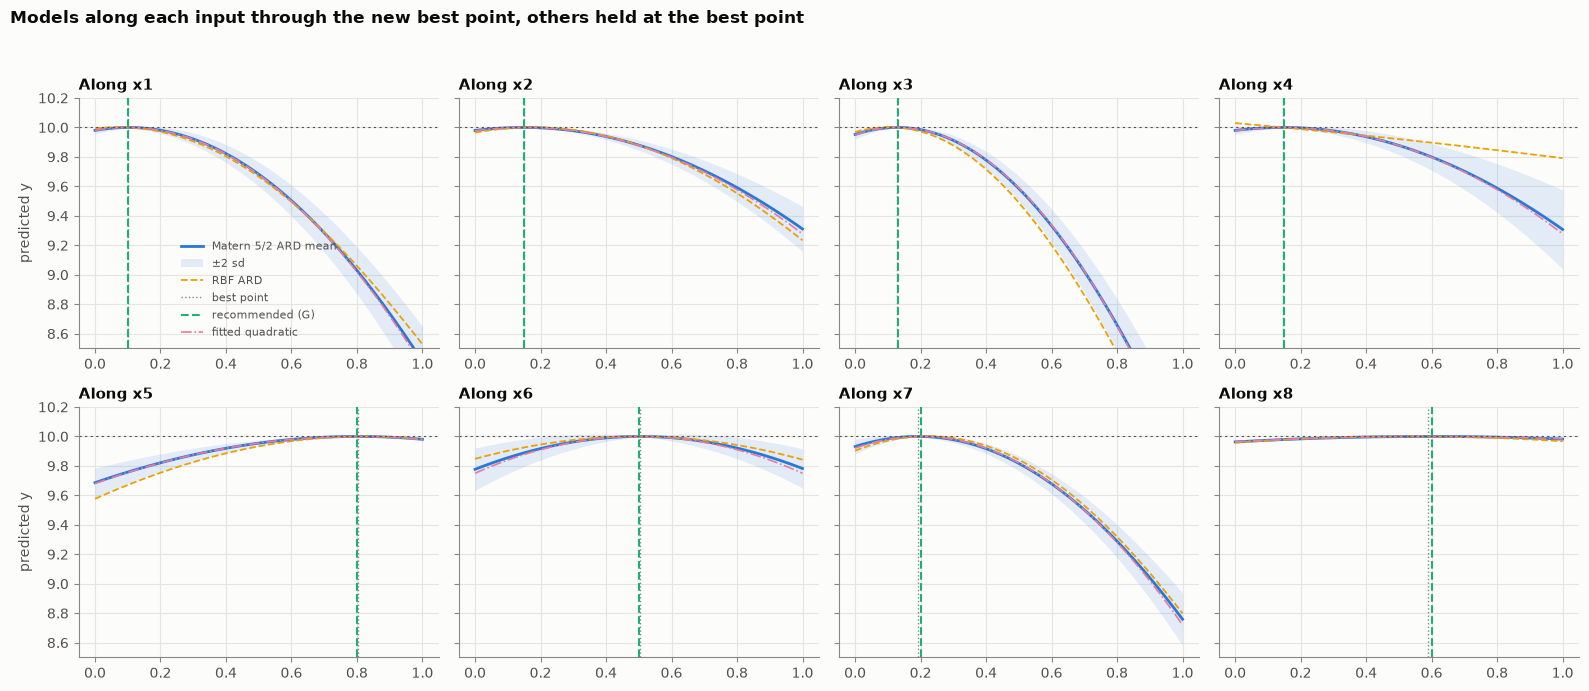

In [10]:
# Fig 5: slices through the best point, recommended model
xB = cands["B: Matern 5/2 max"]
xG = cands["G: vertex of the fitted quadratic"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharey=True)
xs = np.linspace(0, 1, 200)
for j, ax in enumerate(axes.flat):
    Z = np.tile(xb, (len(xs), 1)); Z[:, j] = xs
    m, s = pmean(Z), psd(Z)
    ax.plot(xs, m, color=PAL[0], lw=2, label="Matern 5/2 ARD mean")
    ax.fill_between(xs, m - 2 * s, m + 2 * s, color=PAL[0], alpha=0.12, lw=0, label="±2 sd")
    ax.plot(xs, pmean(Z, "RBF ARD"), color=PAL[3], lw=1.3, ls="--", label="RBF ARD")
    ax.axvline(xb[j], color=MUTED, lw=1, ls=":", label="best point")
    ax.axvline(xG[j], color=PAL[2], lw=1.5, ls="--", label="recommended (G)")
    ax.plot(xs, q_M - q_w[j] * (xs - q_c[j]) ** 2 - sum(q_w[i] * (xb[i] - q_c[i]) ** 2 for i in range(d) if i != j),
            color=PAL[4], lw=1.2, ls="-.", label="fitted quadratic")
    ax.axhline(y[best], color=INK2, lw=0.8, ls=(0, (2, 3)))
    ax.set_title(f"Along x{j + 1}"); ax.set_ylim(8.5, 10.2)
axes[0, 0].set_ylabel("predicted y"); axes[1, 0].set_ylabel("predicted y")
axes[0, 0].legend(frameon=False, fontsize=8, loc="lower center", labelcolor=INK2)
fig.suptitle("Models along each input through the new best point, others held at the best point",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95))

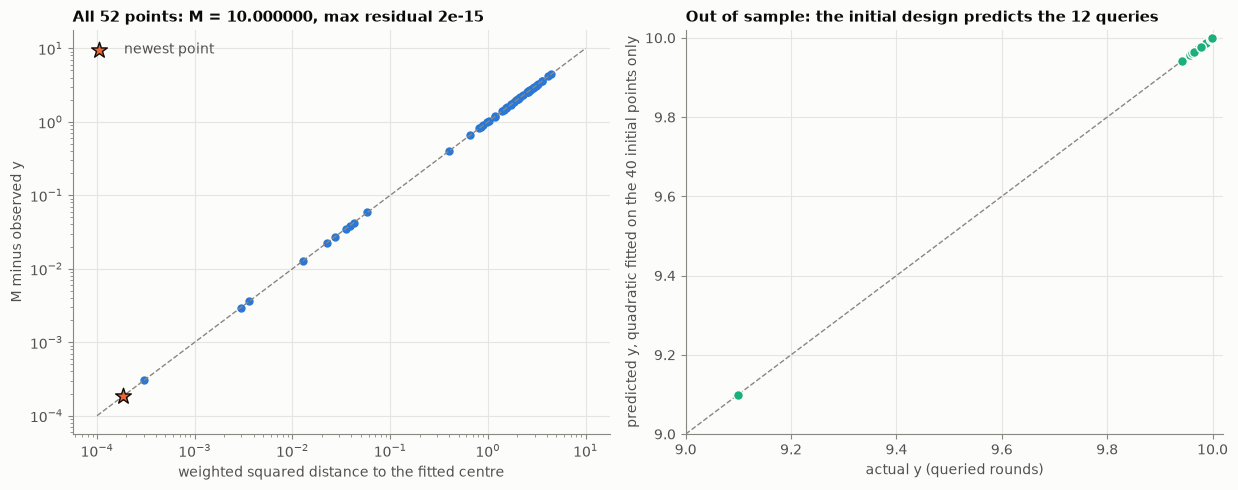

In [11]:
# Fig 6: the fitted quadratic
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 5))
deficit = q_M - y
fitted = ((X - q_c) ** 2 * q_w).sum(1)
a1.loglog(np.maximum(fitted, 1e-8), np.maximum(deficit, 1e-8), "o", color=PAL[0], ms=5)
a1.plot([1e-4, 1e1], [1e-4, 1e1], color=MUTED, ls="--", lw=1)
a1.scatter(np.maximum(fitted[NEW], 1e-8), np.maximum(deficit[NEW], 1e-8), s=140, marker="*", color=PAL[1], edgecolor=INK, zorder=5, label="newest point")
a1.set_xlabel("weighted squared distance to the fitted centre"); a1.set_ylabel("M minus observed y")
a1.set_title(f"All {n} points: M = {q_M:.6f}, max residual {np.abs(q_res).max():.0e}"); a1.legend(frameon=False, labelcolor=INK2)
a2.plot([9.0, 10.0], [9.0, 10.0], color=MUTED, ls="--", lw=1)
a2.scatter(qo_true, qo_pred, s=50, color=PAL[2], edgecolor=SURFACE, zorder=3)
a2.set_xlim(9.0, 10.02); a2.set_ylim(9.0, 10.02)
a2.set_xlabel("actual y (queried rounds)"); a2.set_ylabel("predicted y, quadratic fitted on the 40 initial points only")
a2.set_title("Out of sample: the initial design predicts the 12 queries")
fig.tight_layout()